In [ ]:
"""
step =
1. from webODM, segment the image with Excess Green method
2. and then the segmented output, run the object detection with CoreML models
3. group "n count" trees into zone (NEED TO DO)
4. and then, calculate VARI from each zone
5. after that, output the json which contains this =
   - coordinate annotation for each zone and tree inside that zone for the original webodm image
   - VARI from each zone
   - ...

6. now i need to think on how to measure the "condifence levels" of VARI output

"""

1/6: Loading image and running ExG segmentation...
2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 34 valid trees (>= 70% size); filtered out 3 partial/half trees.
3/6: Calculating VARI map and tree-level statistics...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
5/6: Coloring ExG tree masks by zone and calculating zone statistics...

--- Zone VARI Summary ---
Zone | Trees | Valid pixels | Mean VARI | Median VARI | Std VARI | MAD VARI | Min VARI | Max VARI
-----+-------+--------------+-----------+-------------+----------+----------+----------+---------
1    | 9     | 403,947      | 0.1820    | 0.1707      | 0.0910   | 0.0515   | -0.1137  | 1.2188  
2    | 6     | 347,835      | 0.1712    | 0.1622      | 0.0844   | 0.0468   | -0.0625  | 0.8936  
3    | 9     | 396,904      | 0.2232    | 0.2101      | 0.0966   | 0.0558   | -0.0291  | 1.2143  
4    | 9     | 394,920      | 0.1997    | 0.1862      | 0.0992   | 0.0548   | -0.0969  | 1.1379  
5 

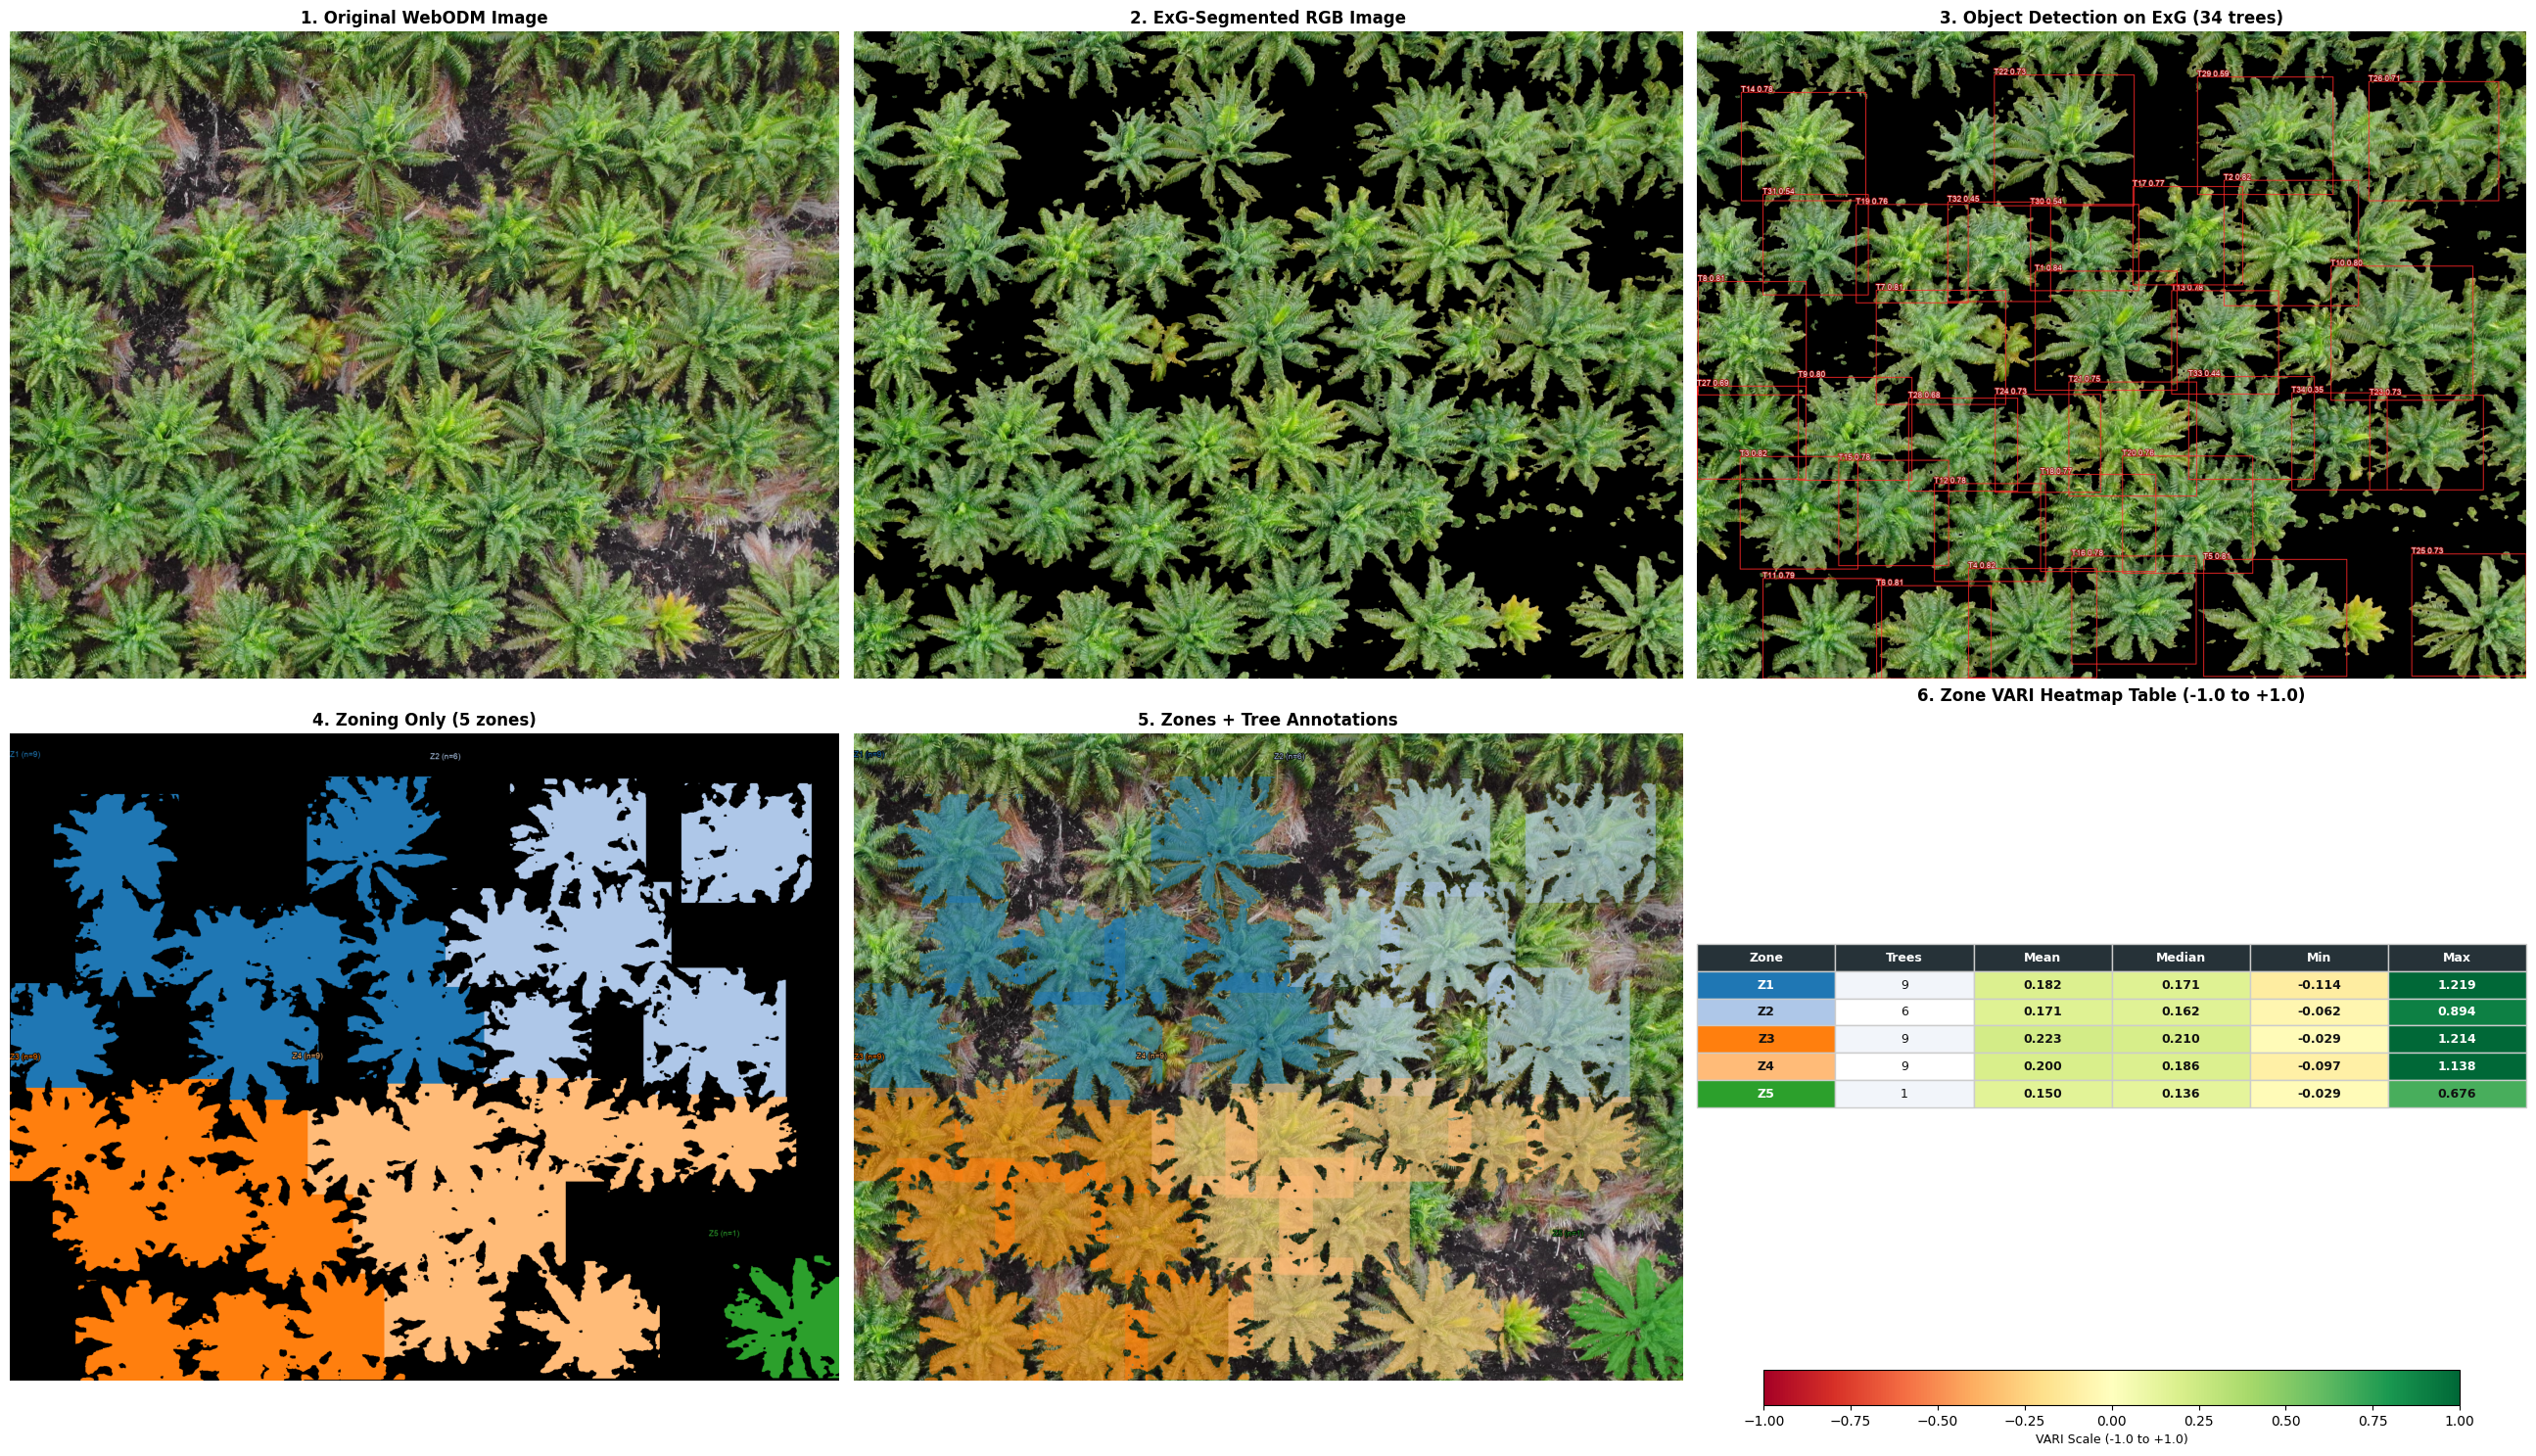

In [19]:
"""Oil-palm zoning + VARI analysis for a WebODM RGB image.

Pipeline:
1. ExG vegetation segmentation
2. CoreML object detection on the ExG-segmented image
3. Spatial grouping of detections into zones containing up to N trees
4. Annotated images for each stage (ExG RGB, CoreML on ExG, and Zones on Original)
5. VARI statistics per tree and per zone, using ExG vegetation pixels
6. JSON and CSV export with pixel and normalized coordinates

Run on macOS with coremltools and the required model installed.
"""

import csv
import json
from pathlib import Path

import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont

# ------------------------- Configuration -------------------------
IMAGE_PATH = "dji_10.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

OUTPUT_JSON = "oil_palm_zones_vari.json"
OUTPUT_ZONE_CSV = "oil_palm_zone_vari_summary.csv"

OUTPUT_EXG_MASK = "oil_palm_exg_mask.png"
OUTPUT_EXG_SEGMENTED = "oil_palm_exg_segmented.jpg"
OUTPUT_COREML_ANNOTATED = "oil_palm_coreml_detections.jpg"
OUTPUT_ZONE_ANNOTATED = "oil_palm_zones_only.jpg"
OUTPUT_ANNOTATED_IMAGE = "oil_palm_zones_annotated.jpg"
OUTPUT_PIPELINE_PLOT = "oil_palm_pipeline_stages.jpg"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
MODEL_INPUT_SIZE = 640

ZONE_GRID_ROWS = 3
ZONE_GRID_COLS = 3
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS
ROW_TOLERANCE_MULTIPLIER = 0.75

MAX_ZONE_DISTANCE_MULTIPLIER = 3.0
ZONE_PADDING_MULTIPLIER = 0.15

MIN_TREE_COMPLETENESS = 0.70  # Keep only trees >= 70% of typical tree size/area
BORDER_MARGIN_PX = 5  

SHOW_PLOTS = True
# -----------------------------------------------------------------


def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.

    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)

    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )

    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)

    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]

    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
):
    """Group nearby palm trees into 3x3 spatial blocks (3 rows x 3 columns, up to 9 trees)."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")

    if not trees:
        return []

    target_trees_per_zone = grid_rows * grid_cols

    # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))

    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))

    # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []

    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")

        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance

        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)

    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])

    # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []

    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)

    if current_band:
        row_bands.append(current_band)

    # 4. Within each 3-row band, slice horizontally into 3-column blocks (up to 9 trees)
    zones = []

    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
        band_trees.sort(key=lambda t: t["center"][0])

        # Split horizontally if there is a wide gap (e.g., road/clearing)
        spatial_clusters = []
        current_cluster = [band_trees[0]]

        for tree in band_trees[1:]:
            dx = tree["center"][0] - current_cluster[-1]["center"][0]
            if dx <= max_zone_distance:
                current_cluster.append(tree)
            else:
                spatial_clusters.append(current_cluster)
                current_cluster = [tree]
        spatial_clusters.append(current_cluster)

        # Slice each contiguous horizontal cluster into 3x3 blocks
        for cluster in spatial_clusters:
            block_capacity = len(band) * grid_cols  # 3 cols per row in the current band

            for offset in range(0, len(cluster), block_capacity):
                members = cluster[offset:offset + block_capacity]

                x1 = min(t["bbox"][0] for t in members) - padding
                y1 = min(t["bbox"][1] for t in members) - padding
                x2 = max(t["bbox"][2] for t in members) + padding
                y2 = max(t["bbox"][3] for t in members) + padding

                if image_width is not None:
                    x1 = max(0, x1)
                    x2 = min(image_width, x2)
                if image_height is not None:
                    y1 = max(0, y1)
                    y2 = min(image_height, y2)

                zones.append({
                    "zone_id": len(zones) + 1,
                    "approx_row": band_idx,
                    "trees": members,
                    "bbox": [x1, y1, x2, y2],
                    "is_undersized": len(members) < target_trees_per_zone,
                })

    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def print_zone_vari_table(zone_json):
    """Print a compact table containing VARI statistics for each zone."""
    columns = [
        ("zone_id", "Zone"),
        ("tree_count", "Trees"),
        ("vegetation_pixel_count", "Valid pixels"),
        ("mean_vari", "Mean VARI"),
        ("median_vari", "Median VARI"),
        ("std_vari", "Std VARI"),
        ("mad_vari", "MAD VARI"),
        ("min_vari", "Min VARI"),
        ("max_vari", "Max VARI"),
    ]

    def fmt(value, digits=4):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)

    rows = []
    for zone in zone_json:
        stats = zone.get("vari", {})
        row = {
            "zone_id": zone.get("zone_id"),
            "tree_count": zone.get("tree_count"),
            "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
            "mean_vari": stats.get("mean_vari"),
            "median_vari": stats.get("median_vari"),
            "std_vari": stats.get("std_vari"),
            "mad_vari": stats.get("mad_vari"),
            "min_vari": stats.get("min_vari"),
            "max_vari": stats.get("max_vari"),
        }
        rows.append([fmt(row[key]) for key, _ in columns])

    widths = [
        max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
        for i, (_, header) in enumerate(columns)
    ]
    header_line = " | ".join(header.ljust(widths[i]) for i, (_, header) in enumerate(columns))
    separator = "-+-".join("-" * width for width in widths)

    print("\n--- Zone VARI Summary ---")
    print(header_line)
    print(separator)
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI statistics to CSV."""
    fieldnames = [
        "zone_id",
        "approx_row",
        "tree_count",
        "bbox_x1",
        "bbox_y1",
        "bbox_x2",
        "bbox_y2",
        "vegetation_pixel_count",
        "mean_vari",
        "median_vari",
        "std_vari",
        "mad_vari",
        "min_vari",
        "max_vari",
    ]

    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox = zone.get("bbox", {})
            stats = zone.get("vari", {})
            writer.writerow({
                "zone_id": zone.get("zone_id"),
                "approx_row": zone.get("approx_row"),
                "tree_count": zone.get("tree_count"),
                "bbox_x1": bbox.get("x1"),
                "bbox_y1": bbox.get("y1"),
                "bbox_x2": bbox.get("x2"),
                "bbox_y2": bbox.get("y2"),
                "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
                "mean_vari": stats.get("mean_vari"),
                "median_vari": stats.get("median_vari"),
                "std_vari": stats.get("std_vari"),
                "mad_vari": stats.get("mad_vari"),
                "min_vari": stats.get("min_vari"),
                "max_vari": stats.get("max_vari"),
            })


def main():
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors

    image_path = Path(IMAGE_PATH)
    model_path = Path(MODEL_PATH)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
    if not model_path.exists():
        raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")

    print("1/6: Loading image and running ExG segmentation...")
    original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    height, width = original_bgr.shape[:2]
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
    segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)

    cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
    cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)

    print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
    model = ct.models.MLModel(str(model_path))
    normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
    raw_trees = []
    for box, score in zip(normalized_boxes, scores):
        bbox = normalized_box_to_pixels(box, width, height)
        bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if bw <= 0 or bh <= 0:
            continue
        raw_trees.append({
            "confidence": float(score),
            "bbox": bbox,
            "width": bw,
            "height": bh,
            "area": bw * bh,
            "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
            "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
        })

    # Reference full-tree size from interior trees (not clipped by image borders)
    interior_trees = [
        t for t in raw_trees
        if t["bbox"][0] > BORDER_MARGIN_PX
        and t["bbox"][1] > BORDER_MARGIN_PX
        and t["bbox"][2] < (width - BORDER_MARGIN_PX)
        and t["bbox"][3] < (height - BORDER_MARGIN_PX)
    ]
    ref_pool = interior_trees if interior_trees else raw_trees

    if ref_pool:
        median_w = float(np.median([t["width"] for t in ref_pool]))
        median_h = float(np.median([t["height"] for t in ref_pool]))
        median_area = float(np.median([t["area"] for t in ref_pool]))
    else:
        median_w = median_h = median_area = 0.0

    # Keep only trees that are at least 70% of typical width, height, and area
    trees = []
    skipped_partial = 0
    for t in raw_trees:
        w_ratio = t["width"] / median_w if median_w > 0 else 1.0
        h_ratio = t["height"] / median_h if median_h > 0 else 1.0
        area_ratio = t["area"] / median_area if median_area > 0 else 1.0

        if (
            w_ratio < MIN_TREE_COMPLETENESS
            or h_ratio < MIN_TREE_COMPLETENESS
            or area_ratio < MIN_TREE_COMPLETENESS
        ):
            skipped_partial += 1
            continue

        t["tree_id"] = len(trees) + 1
        trees.append(t)

    print(
        f"Detected {len(trees)} valid trees (>= {int(MIN_TREE_COMPLETENESS * 100)}% size); "
        f"filtered out {skipped_partial} partial/half trees."
    )

    print("3/6: Calculating VARI map and tree-level statistics...")
    b, g, r = cv2.split(original_bgr)
    b = b.astype(np.float32)
    g = g.astype(np.float32)
    r = r.astype(np.float32)
    denominator = g + r - b
    vari_map = np.full((height, width), np.nan, dtype=np.float32)
    valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
    np.divide(g - r, denominator, out=vari_map, where=valid)

    for tree in trees:
        tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
        tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)

    print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
    zones = group_trees_into_zones(
        trees,
        grid_rows=ZONE_GRID_ROWS,
        grid_cols=ZONE_GRID_COLS,
        row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
        max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
        zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
        image_width=width,
        image_height=height,
    )

    print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
    try:
        font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
    except OSError:
        font = ImageFont.load_default()

    tree_line_width = max(2, width // 1500)
    MASK_OVERLAY_ALPHA = 0.60

    # Image 3: CoreML object detections drawn on the ExG-segmented RGB image
    coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
    draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
    for tree in trees:
        tb = tree["bbox"]
        draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
        tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
        tx, ty = tb[0], max(0, tb[1] - 18)
        draw_coreml_exg.text(
            (tx, ty), tree_label,
            fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
        )
    coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)

    # Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
    zone_tree_mask_rgb = np.zeros_like(original_rgb)

    # Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
    zone_tree_overlay_rgb = original_rgb.copy()

    cmap_zones = plt.colormaps["tab20"]
    zone_label_positions = []
    zone_json = []

    for zone in zones:
        zb = zone["bbox"]
        zx1, zy1, zx2, zy2 = zb
        tree_records = []

        # Pick a unique RGB color for this zone
        rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
        zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
        zone_color = tuple(int(v) for v in zone_color_u8)

        # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
        tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)

        for tree in zone["trees"]:
            tx1, ty1, tx2, ty2 = tree["bbox"]
            tree_records.append({
                "tree_id": tree["tree_id"],
                "confidence": tree["confidence"],
                "bbox": tree["bbox_annotation"],
                "vari": tree["vari"],
            })

            # Get ExG mask pixels inside this tree's detection area
            tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0

            # 1) Color the tree's ExG mask pixels on the black canvas
            zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8

            # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
            orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
            orig_crop[tree_exg_mask] = (
                orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
                + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
            ).astype(np.uint8)

            # Mark this tree's region inside the zone union mask
            lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
            lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
            if lx2 > lx1 and ly2 > ly1:
                tree_box_union[ly1:ly2, lx1:lx2] = True

        # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
        vari_crop = vari_map[zy1:zy2, zx1:zx2]
        mask_crop = (exg_mask[zy1:zy2, zx1:zy2 if False else zx2] > 0) & tree_box_union
        valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
        if valid_vals.size == 0:
            zone_stats = {
                "vegetation_pixel_count": 0,
                "mean_vari": None, "median_vari": None,
                "std_vari": None, "mad_vari": None,
                "min_vari": None, "max_vari": None,
            }
        else:
            med = float(np.median(valid_vals))
            zone_stats = {
                "vegetation_pixel_count": int(valid_vals.size),
                "mean_vari": float(np.mean(valid_vals)),
                "median_vari": med,
                "std_vari": float(np.std(valid_vals)),
                "mad_vari": float(np.median(np.abs(valid_vals - med))),
                "min_vari": float(np.min(valid_vals)),
                "max_vari": float(np.max(valid_vals)),
            }

        zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
        zx, zy = zx1, max(0, zy1 - 28)
        zone_label_positions.append((zx, zy, zone_label, zone_color))

        zone_json.append({
            "zone_id": zone["zone_id"],
            "approx_row": zone["approx_row"],
            "tree_count": len(tree_records),
            "bbox": pixel_bbox_record(zb, width, height),
            "vari": zone_stats,
            "trees": tree_records,
        })

    zones_only_img = Image.fromarray(zone_tree_mask_rgb)
    draw_zones_only = ImageDraw.Draw(zones_only_img)

    combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
    draw_combined = ImageDraw.Draw(combined_annotated_img)

    # Draw only the Zone ID text labels (no bounding boxes)
    for zx, zy, zone_label, zone_color in zone_label_positions:
        for canvas in (draw_zones_only, draw_combined):
            canvas.text(
                (zx, zy), zone_label,
                fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
            )

    zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
    combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)

    # Save CSV and print summary table
    save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
    print_zone_vari_table(zone_json)

    # Save JSON
    result = {
        "metadata": {
            "source_image": str(image_path),
            "image_width_px": width,
            "image_height_px": height,
            "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
            "vari_formula": "(G - R) / (G + R - B)",
            "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
            "model_path": str(model_path),
            "confidence_threshold": CONF_THRESHOLD,
            "nms_iou_threshold": IOU_THRESHOLD,
            "trees_per_zone_max": TREES_PER_ZONE,
            "zone_grouping": "Approximate image-row clustering, then left-to-right chunks; each zone is the rectangle enclosing its member tree boxes",
            "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
            "detected_tree_count": len(trees),
            "zone_count": len(zone_json),
            "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary. normalized_xyxy values are divided by original image width/height.",
            "limitations": [
                "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
                "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
                "Zone VARI summarizes the entire rectangular zone's ExG-selected pixels, which may include vegetation between tree boxes. Use tree-only aggregation instead if that is the intended zone definition.",
                "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
            ],
        },
        "zones": zone_json,
    }
    with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)

    # Build and save the 2x3 visualization figure (5 images + 1 VARI Heatmap Table)
    fig, axes = plt.subplots(2, 3, figsize=(26, 15))

    axes[0][0].imshow(original_rgb)
    axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
    axes[0][0].axis("off")

    axes[0][1].imshow(segmented_rgb)
    axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
    axes[0][1].axis("off")

    axes[0][2].imshow(coreml_on_exg_img)
    axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
    axes[0][2].axis("off")

    axes[1][0].imshow(zones_only_img)
    axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
    axes[1][0].axis("off")

    axes[1][1].imshow(combined_annotated_img)
    axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
    axes[1][1].axis("off")

    # 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
    ax_table = axes[1][2]
    ax_table.axis("off")
    ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")

    if zone_json:
        cmap_vari = plt.colormaps["RdYlGn"]
        norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
        col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
        heatmap_cols = {2, 3, 4, 5}

        cell_text, cell_colors, text_colors = [], [], []
        for r_idx, z in enumerate(zone_json):
            st = z.get("vari", {})
            vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
            row_str = [
                f"Z{z['zone_id']}",
                str(z["tree_count"]),
                *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
            ]
            raw_row = [None, None, *vals]
            base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
            r_bg, r_fg = [], []
            for c_idx, v in enumerate(raw_row):
                if c_idx == 0:
                    z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                    r_bg.append(z_rgba)
                    lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                    rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                    r_bg.append(rgba)
                    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                else:
                    r_bg.append(base_bg)
                    r_fg.append("#111111")
            cell_text.append(row_str)
            cell_colors.append(r_bg)
            text_colors.append(r_fg)

        tbl = ax_table.table(
            cellText=cell_text,
            colLabels=col_labels,
            cellColours=cell_colors,
            cellLoc="center",
            loc="center",
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1.0, 1.35)

        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            if r == 0:
                cell.set_facecolor("#263238")
                cell.get_text().set_color("white")
                cell.get_text().set_weight("bold")
            else:
                cell.get_text().set_color(text_colors[r - 1][c])
                if c in heatmap_cols or c == 0:
                    cell.get_text().set_weight("bold")

        sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
        cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
        cbar.set_ticks(np.linspace(-1.0, 1.0, 9))

    plt.tight_layout()
    fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")

    print("\n6/6: Outputs written:")
    print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
    print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
    print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
    print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
    print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
    print(f"  6. 6-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
    print(f"  7. JSON output:              {Path(OUTPUT_JSON).resolve()}")
    print(f"  8. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


if __name__ == "__main__":
    main()


1/6: Loading image and running ExG segmentation...
2/6: Loading CoreML model and detecting trees on ExG-segmented image...
Detected 12 valid trees (>= 70% size); filtered out 3 partial/half trees.
3/6: Calculating VARI map and tree-level statistics...
4/6: Grouping trees into 3x3 zones (up to 9 trees/zone)...
5/6: Coloring ExG tree masks by zone and calculating zone statistics...

--- Zone VARI Summary ---
Zone | Trees | Valid pixels | Mean VARI | Median VARI | Std VARI | MAD VARI | Min VARI | Max VARI
-----+-------+--------------+-----------+-------------+----------+----------+----------+---------
1    | 9     | 416,855      | 0.1912    | 0.1810      | 0.0870   | 0.0503   | -0.0586  | 1.1026  
2    | 3     | 157,485      | 0.1590    | 0.1512      | 0.0720   | 0.0420   | -0.0400  | 0.9649  

6/6: Outputs written:
  1. ExG mask:                 /Users/putragandadewata/Desktop/ADA_IL_Challenge/Krops-Challenge6/machine_learning_krops_final_git/segmentation/final_flow/oil_palm_exg_mask.png

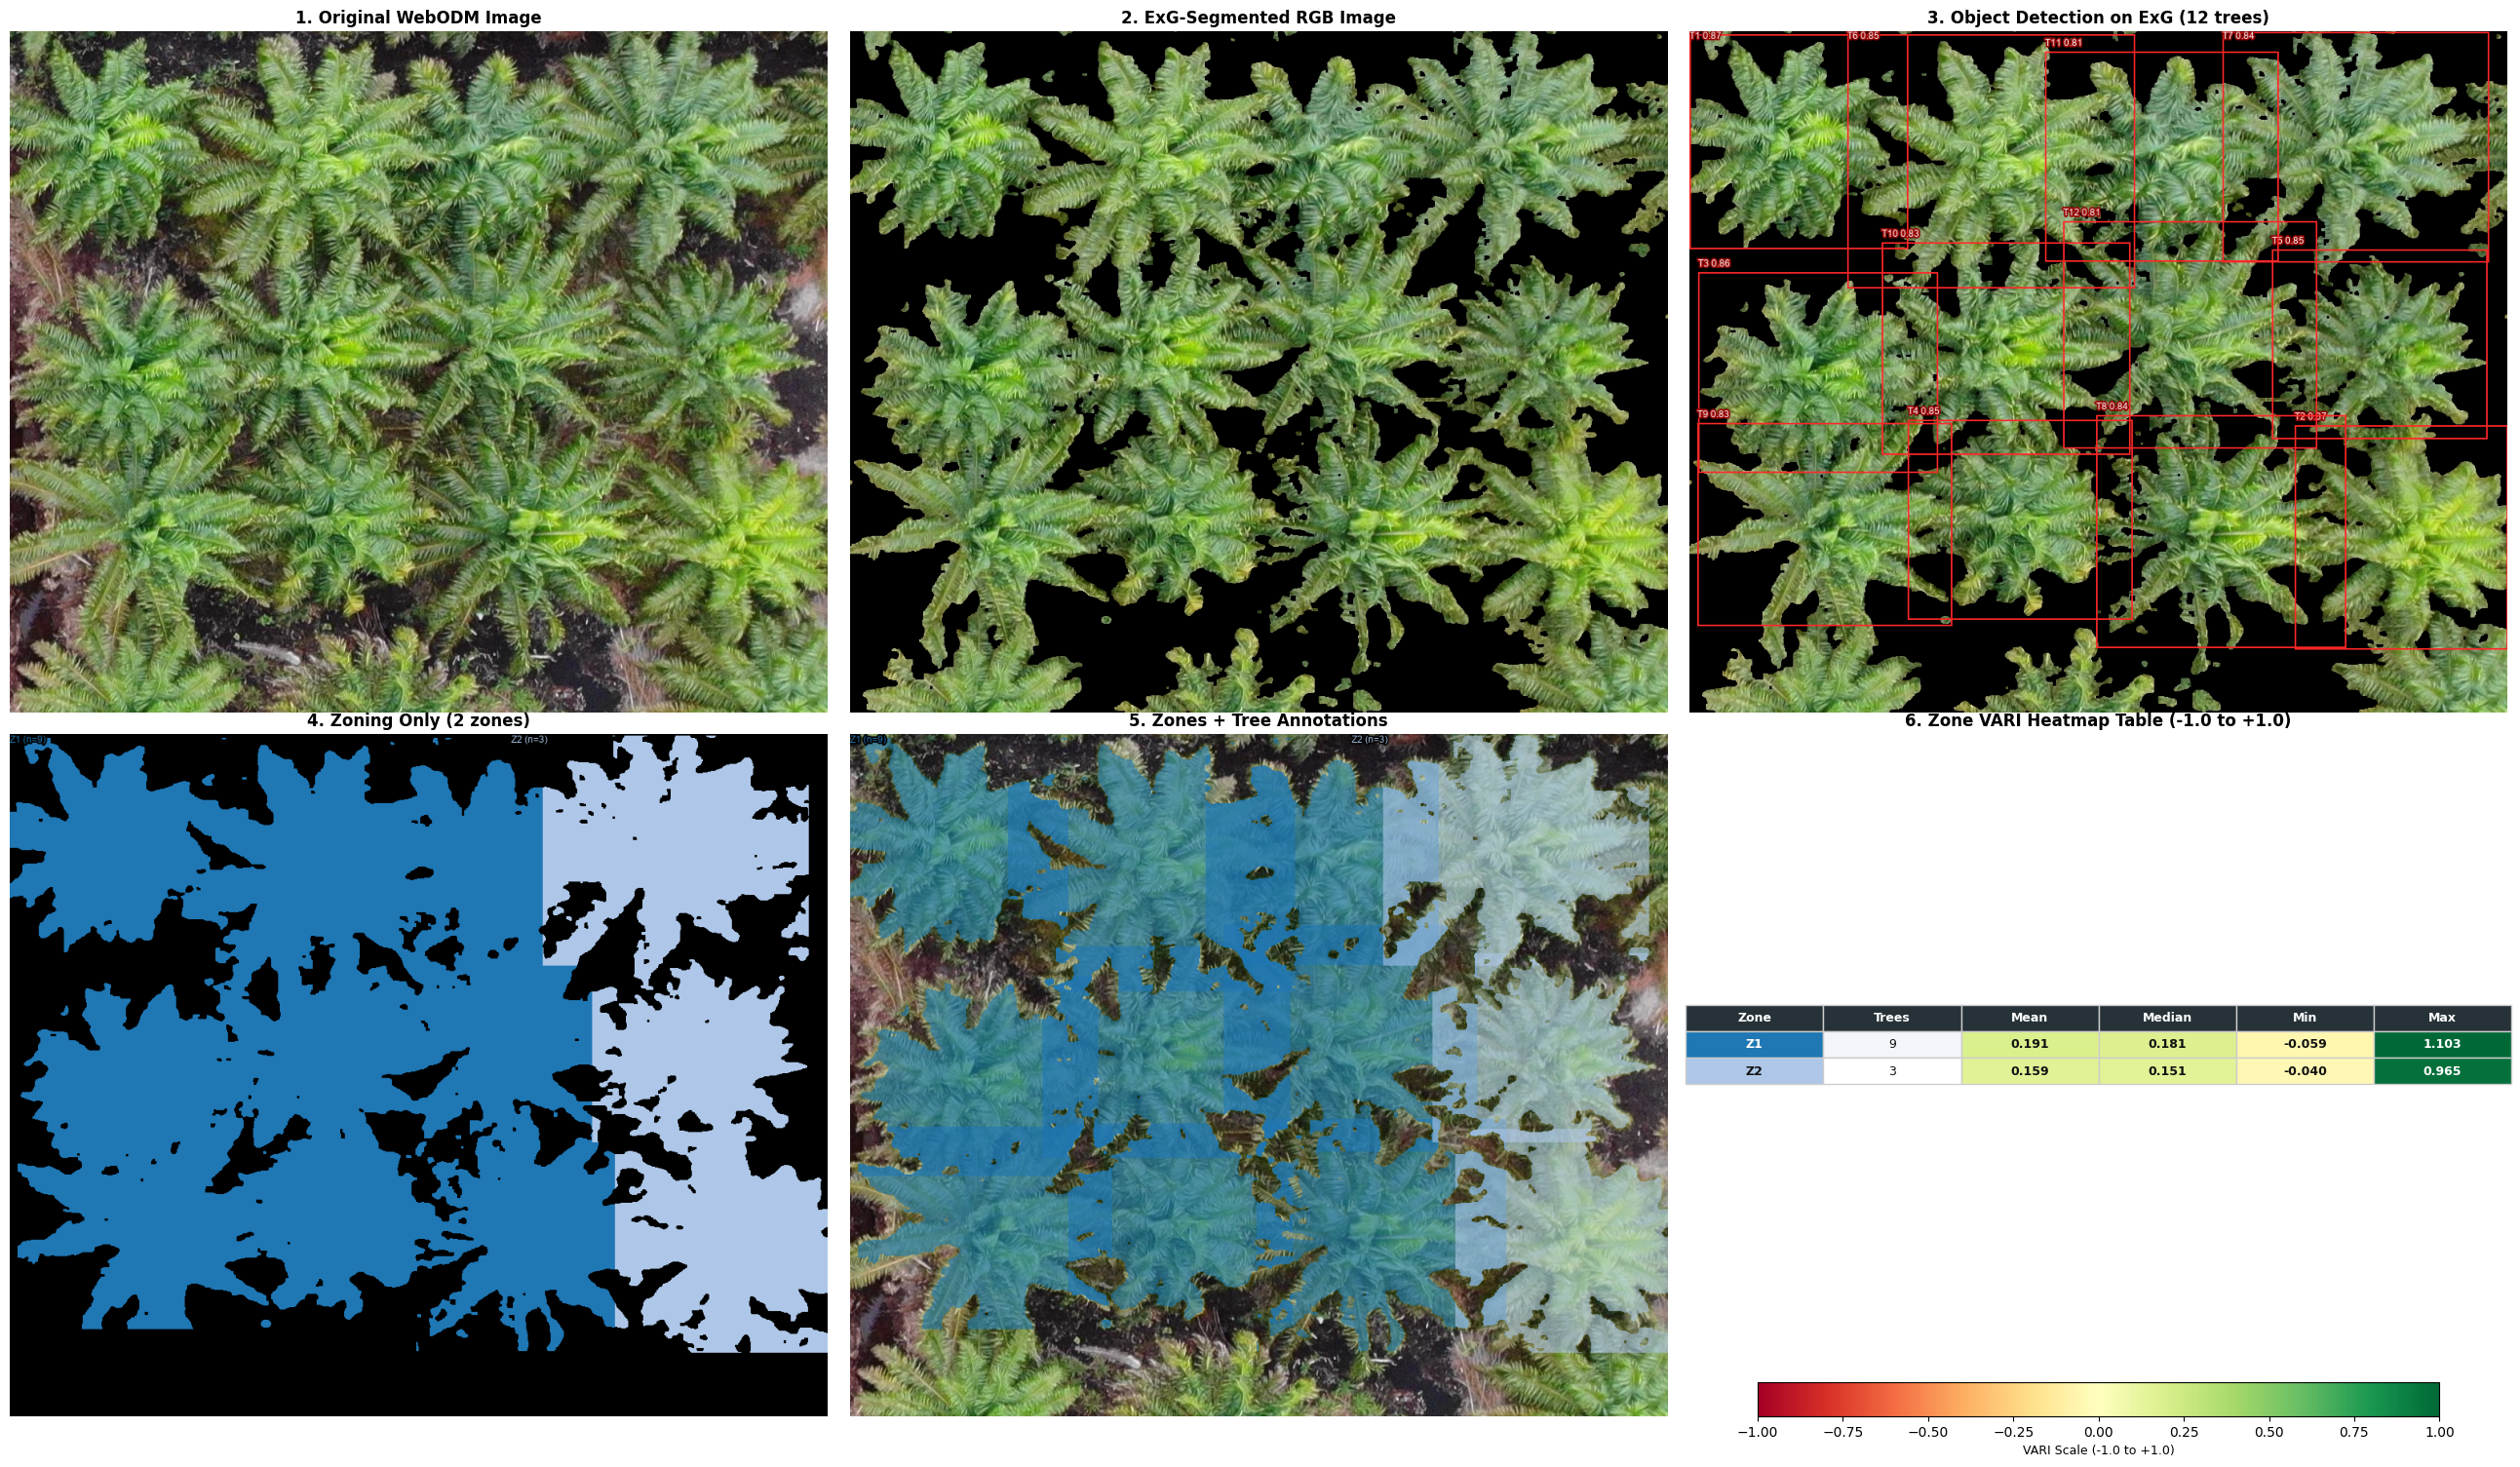

In [20]:
"""Oil-palm zoning + VARI analysis for a WebODM RGB image.

Pipeline:
1. ExG vegetation segmentation
2. CoreML object detection on the ExG-segmented image
3. Spatial grouping of detections into zones containing up to N trees
4. Annotated images for each stage (ExG RGB, CoreML on ExG, and Zones on Original)
5. VARI statistics per tree and per zone, using ExG vegetation pixels
6. JSON and CSV export with pixel and normalized coordinates

Run on macOS with coremltools and the required model installed.
"""

import csv
import json
from pathlib import Path

import coremltools as ct
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageFont

# ------------------------- Configuration -------------------------
IMAGE_PATH = "dji_15.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

OUTPUT_JSON = "oil_palm_zones_vari.json"
OUTPUT_ZONE_CSV = "oil_palm_zone_vari_summary.csv"

OUTPUT_EXG_MASK = "oil_palm_exg_mask.png"
OUTPUT_EXG_SEGMENTED = "oil_palm_exg_segmented.jpg"
OUTPUT_COREML_ANNOTATED = "oil_palm_coreml_detections.jpg"
OUTPUT_ZONE_ANNOTATED = "oil_palm_zones_only.jpg"
OUTPUT_ANNOTATED_IMAGE = "oil_palm_zones_annotated.jpg"
OUTPUT_PIPELINE_PLOT = "oil_palm_pipeline_stages.jpg"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45
MODEL_INPUT_SIZE = 640

ZONE_GRID_ROWS = 3
ZONE_GRID_COLS = 3
TREES_PER_ZONE = ZONE_GRID_ROWS * ZONE_GRID_COLS
ROW_TOLERANCE_MULTIPLIER = 0.75

MAX_ZONE_DISTANCE_MULTIPLIER = 3.0
ZONE_PADDING_MULTIPLIER = 0.15

MIN_TREE_COMPLETENESS = 0.70  # Keep only trees >= 70% of typical tree size/area
BORDER_MARGIN_PX = 5  

SHOW_PLOTS = True
# -----------------------------------------------------------------


def iou(box1, box2):
    x1, y1 = max(box1[0], box2[0]), max(box1[1], box2[1])
    x2, y2 = min(box1[2], box2[2]), min(box1[3], box2[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def nms(boxes, scores, iou_threshold=0.45):
    if not boxes:
        return []
    order = np.argsort(scores)[::-1]
    selected = []
    while len(order) > 0:
        current = int(order[0])
        selected.append(current)
        order = np.asarray([
            int(j) for j in order[1:]
            if iou(boxes[current], boxes[int(j)]) <= iou_threshold
        ], dtype=int)
    return selected


def segment_vegetation_exg(image_bgr):
    """Create an ExG/Otsu mask. This is a heuristic vegetation mask, not a crown model."""
    b, g, r = cv2.split(image_bgr)
    exg = 2.0 * g.astype(np.float32) - r.astype(np.float32) - b.astype(np.float32)
    exg_u8 = cv2.normalize(exg, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, mask = cv2.threshold(exg_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    segmented = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return mask, segmented


def parse_coreml_predictions(model, rgb_image):
    """Parse the [1, 5, N] / [1, N, 5] single-class output assumed by the source script.

    Expected prediction rows: [cx, cy, width, height, confidence] in 640x640 pixels.
    """
    input_names = list(model.input_description)
    if not input_names:
        raise RuntimeError("The CoreML model has no declared input.")
    pil_image = Image.fromarray(rgb_image).convert("RGB").resize(
        (MODEL_INPUT_SIZE, MODEL_INPUT_SIZE)
    )
    prediction = model.predict({input_names[0]: pil_image})
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    raw = np.squeeze(raw)

    if raw.ndim != 2:
        raise ValueError(f"Unexpected model output shape {raw.shape}; expected a 2D array after squeeze.")
    if raw.shape[0] == 5:
        rows = raw.T
    elif raw.shape[1] == 5:
        rows = raw
    else:
        raise ValueError(
            f"Model output shape {raw.shape} does not have a 5-value detection axis. "
            "Inspect the CoreML output schema and update parse_coreml_predictions()."
        )

    boxes, scores = [], []
    for row in rows:
        cx, cy, width, height, confidence = map(float, row[:5])
        if not np.isfinite([cx, cy, width, height, confidence]).all() or confidence < CONF_THRESHOLD:
            continue
        box = [
            np.clip((cx - width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy - height / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cx + width / 2) / MODEL_INPUT_SIZE, 0, 1),
            np.clip((cy + height / 2) / MODEL_INPUT_SIZE, 0, 1),
        ]
        if box[2] > box[0] and box[3] > box[1]:
            boxes.append([float(v) for v in box])
            scores.append(confidence)

    keep = nms(boxes, scores, IOU_THRESHOLD)
    return [boxes[i] for i in keep], [scores[i] for i in keep]


def normalized_box_to_pixels(box, width, height):
    x1, y1, x2, y2 = box
    return [
        max(0, min(width, int(round(x1 * width)))),
        max(0, min(height, int(round(y1 * height)))),
        max(0, min(width, int(round(x2 * width)))),
        max(0, min(height, int(round(y2 * height)))),
    ]


def stats_for_box(vari_map, exg_mask, bbox):
    x1, y1, x2, y2 = bbox
    if x2 <= x1 or y2 <= y1:
        values = np.asarray([], dtype=np.float32)
    else:
        vari_crop = vari_map[y1:y2, x1:x2]
        mask_crop = exg_mask[y1:y2, x1:x2] > 0
        values = vari_crop[mask_crop & np.isfinite(vari_crop)]

    if values.size == 0:
        return {
            "vegetation_pixel_count": 0,
            "mean_vari": None,
            "median_vari": None,
            "std_vari": None,
            "mad_vari": None,
            "min_vari": None,
            "max_vari": None,
        }
    median = float(np.median(values))
    return {
        "vegetation_pixel_count": int(values.size),
        "mean_vari": float(np.mean(values)),
        "median_vari": median,
        "std_vari": float(np.std(values)),
        "mad_vari": float(np.median(np.abs(values - median))),
        "min_vari": float(np.min(values)),
        "max_vari": float(np.max(values)),
    }


def group_trees_into_zones(
    trees,
    grid_rows=3,
    grid_cols=3,
    row_tolerance_multiplier=0.75,
    max_zone_distance_multiplier=3.0,
    zone_padding_multiplier=0.15,
    image_width=None,
    image_height=None,
):
    """Group nearby palm trees into 3x3 spatial blocks (3 rows x 3 columns, up to 9 trees)."""
    if grid_rows < 1 or grid_cols < 1:
        raise ValueError("grid_rows and grid_cols must be at least 1.")

    if not trees:
        return []

    target_trees_per_zone = grid_rows * grid_cols

    # 1. Estimate typical tree size
    heights = [max(1, tree["bbox"][3] - tree["bbox"][1]) for tree in trees]
    median_height = float(np.median(heights))

    row_tolerance = max(1.0, median_height * row_tolerance_multiplier)
    max_zone_distance = max(1.0, median_height * max_zone_distance_multiplier)
    padding = max(0, int(median_height * zone_padding_multiplier))

    # 2. Cluster trees into approximate horizontal rows
    ordered = sorted(trees, key=lambda tree: (tree["center"][1], tree["center"][0]))
    rows = []

    for tree in ordered:
        cy = tree["center"][1]
        best_row = None
        best_distance = float("inf")

        for row in rows:
            row_center = float(np.median([item["center"][1] for item in row]))
            distance = abs(cy - row_center)
            if distance <= row_tolerance and distance < best_distance:
                best_row = row
                best_distance = distance

        if best_row is None:
            rows.append([tree])
        else:
            best_row.append(tree)

    rows.sort(key=lambda row: float(np.median([tree["center"][1] for tree in row])))
    for row in rows:
        row.sort(key=lambda tree: tree["center"][0])

    # 3. Group consecutive rows into bands of up to `grid_rows` (3 rows)
    row_bands = []
    current_band = []

    for row in rows:
        if not current_band:
            current_band.append(row)
        else:
            prev_row_y = float(np.median([t["center"][1] for t in current_band[-1]]))
            curr_row_y = float(np.median([t["center"][1] for t in row]))
            if len(current_band) >= grid_rows or (curr_row_y - prev_row_y) > max_zone_distance:
                row_bands.append(current_band)
                current_band = [row]
            else:
                current_band.append(row)

    if current_band:
        row_bands.append(current_band)

    # 4. Within each 3-row band, slice horizontally into 3-column blocks (up to 9 trees)
    zones = []

    for band_idx, band in enumerate(row_bands, start=1):
        band_trees = [tree for row in band for tree in row]
        band_trees.sort(key=lambda t: t["center"][0])

        # Split horizontally if there is a wide gap (e.g., road/clearing)
        spatial_clusters = []
        current_cluster = [band_trees[0]]

        for tree in band_trees[1:]:
            dx = tree["center"][0] - current_cluster[-1]["center"][0]
            if dx <= max_zone_distance:
                current_cluster.append(tree)
            else:
                spatial_clusters.append(current_cluster)
                current_cluster = [tree]
        spatial_clusters.append(current_cluster)

        # Slice each contiguous horizontal cluster into 3x3 blocks
        for cluster in spatial_clusters:
            block_capacity = len(band) * grid_cols  # 3 cols per row in the current band

            for offset in range(0, len(cluster), block_capacity):
                members = cluster[offset:offset + block_capacity]

                x1 = min(t["bbox"][0] for t in members) - padding
                y1 = min(t["bbox"][1] for t in members) - padding
                x2 = max(t["bbox"][2] for t in members) + padding
                y2 = max(t["bbox"][3] for t in members) + padding

                if image_width is not None:
                    x1 = max(0, x1)
                    x2 = min(image_width, x2)
                if image_height is not None:
                    y1 = max(0, y1)
                    y2 = min(image_height, y2)

                zones.append({
                    "zone_id": len(zones) + 1,
                    "approx_row": band_idx,
                    "trees": members,
                    "bbox": [x1, y1, x2, y2],
                    "is_undersized": len(members) < target_trees_per_zone,
                })

    return zones


def pixel_bbox_record(bbox, image_width, image_height):
    x1, y1, x2, y2 = map(int, bbox)
    return {
        "x1": x1, "y1": y1, "x2": x2, "y2": y2,
        "width": x2 - x1,
        "height": y2 - y1,
        "normalized_xyxy": [
            x1 / image_width, y1 / image_height,
            x2 / image_width, y2 / image_height,
        ],
    }


def print_zone_vari_table(zone_json):
    """Print a compact table containing VARI statistics for each zone."""
    columns = [
        ("zone_id", "Zone"),
        ("tree_count", "Trees"),
        ("vegetation_pixel_count", "Valid pixels"),
        ("mean_vari", "Mean VARI"),
        ("median_vari", "Median VARI"),
        ("std_vari", "Std VARI"),
        ("mad_vari", "MAD VARI"),
        ("min_vari", "Min VARI"),
        ("max_vari", "Max VARI"),
    ]

    def fmt(value, digits=4):
        if value is None:
            return "N/A"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{digits}f}" if np.isfinite(value) else "N/A"
        return str(value)

    rows = []
    for zone in zone_json:
        stats = zone.get("vari", {})
        row = {
            "zone_id": zone.get("zone_id"),
            "tree_count": zone.get("tree_count"),
            "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
            "mean_vari": stats.get("mean_vari"),
            "median_vari": stats.get("median_vari"),
            "std_vari": stats.get("std_vari"),
            "mad_vari": stats.get("mad_vari"),
            "min_vari": stats.get("min_vari"),
            "max_vari": stats.get("max_vari"),
        }
        rows.append([fmt(row[key]) for key, _ in columns])

    widths = [
        max(len(header), *(len(row[i]) for row in rows)) if rows else len(header)
        for i, (_, header) in enumerate(columns)
    ]
    header_line = " | ".join(header.ljust(widths[i]) for i, (_, header) in enumerate(columns))
    separator = "-+-".join("-" * width for width in widths)

    print("\n--- Zone VARI Summary ---")
    print(header_line)
    print(separator)
    if not rows:
        print("(No zones were created.)")
    else:
        for row in rows:
            print(" | ".join(value.ljust(widths[i]) for i, value in enumerate(row)))


def save_zone_vari_csv(zone_json, output_path):
    """Save one row per zone with VARI statistics to CSV."""
    fieldnames = [
        "zone_id",
        "approx_row",
        "tree_count",
        "bbox_x1",
        "bbox_y1",
        "bbox_x2",
        "bbox_y2",
        "vegetation_pixel_count",
        "mean_vari",
        "median_vari",
        "std_vari",
        "mad_vari",
        "min_vari",
        "max_vari",
    ]

    with open(output_path, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
        writer.writeheader()
        for zone in zone_json:
            bbox = zone.get("bbox", {})
            stats = zone.get("vari", {})
            writer.writerow({
                "zone_id": zone.get("zone_id"),
                "approx_row": zone.get("approx_row"),
                "tree_count": zone.get("tree_count"),
                "bbox_x1": bbox.get("x1"),
                "bbox_y1": bbox.get("y1"),
                "bbox_x2": bbox.get("x2"),
                "bbox_y2": bbox.get("y2"),
                "vegetation_pixel_count": stats.get("vegetation_pixel_count"),
                "mean_vari": stats.get("mean_vari"),
                "median_vari": stats.get("median_vari"),
                "std_vari": stats.get("std_vari"),
                "mad_vari": stats.get("mad_vari"),
                "min_vari": stats.get("min_vari"),
                "max_vari": stats.get("max_vari"),
            })


def main():
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors

    image_path = Path(IMAGE_PATH)
    model_path = Path(MODEL_PATH)
    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path.resolve()}")
    if not model_path.exists():
        raise FileNotFoundError(f"CoreML model not found: {model_path.resolve()}")

    print("1/6: Loading image and running ExG segmentation...")
    original_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if original_bgr is None:
        raise ValueError(f"Could not read image: {image_path}")
    height, width = original_bgr.shape[:2]
    original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
    exg_mask, segmented_bgr = segment_vegetation_exg(original_bgr)
    segmented_rgb = cv2.cvtColor(segmented_bgr, cv2.COLOR_BGR2RGB)

    cv2.imwrite(OUTPUT_EXG_MASK, exg_mask)
    cv2.imwrite(OUTPUT_EXG_SEGMENTED, segmented_bgr)

    print("2/6: Loading CoreML model and detecting trees on ExG-segmented image...")
    model = ct.models.MLModel(str(model_path))
    normalized_boxes, scores = parse_coreml_predictions(model, segmented_rgb)
    raw_trees = []
    for box, score in zip(normalized_boxes, scores):
        bbox = normalized_box_to_pixels(box, width, height)
        bw, bh = bbox[2] - bbox[0], bbox[3] - bbox[1]
        if bw <= 0 or bh <= 0:
            continue
        raw_trees.append({
            "confidence": float(score),
            "bbox": bbox,
            "width": bw,
            "height": bh,
            "area": bw * bh,
            "center": ((bbox[0] + bbox[2]) / 2.0, (bbox[1] + bbox[3]) / 2.0),
            "bbox_normalized": [bbox[0] / width, bbox[1] / height, bbox[2] / width, bbox[3] / height],
        })

    # Reference full-tree size from interior trees (not clipped by image borders)
    interior_trees = [
        t for t in raw_trees
        if t["bbox"][0] > BORDER_MARGIN_PX
        and t["bbox"][1] > BORDER_MARGIN_PX
        and t["bbox"][2] < (width - BORDER_MARGIN_PX)
        and t["bbox"][3] < (height - BORDER_MARGIN_PX)
    ]
    ref_pool = interior_trees if interior_trees else raw_trees

    if ref_pool:
        median_w = float(np.median([t["width"] for t in ref_pool]))
        median_h = float(np.median([t["height"] for t in ref_pool]))
        median_area = float(np.median([t["area"] for t in ref_pool]))
    else:
        median_w = median_h = median_area = 0.0

    # Keep only trees that are at least 70% of typical width, height, and area
    trees = []
    skipped_partial = 0
    for t in raw_trees:
        w_ratio = t["width"] / median_w if median_w > 0 else 1.0
        h_ratio = t["height"] / median_h if median_h > 0 else 1.0
        area_ratio = t["area"] / median_area if median_area > 0 else 1.0

        if (
            w_ratio < MIN_TREE_COMPLETENESS
            or h_ratio < MIN_TREE_COMPLETENESS
            or area_ratio < MIN_TREE_COMPLETENESS
        ):
            skipped_partial += 1
            continue

        t["tree_id"] = len(trees) + 1
        trees.append(t)

    print(
        f"Detected {len(trees)} valid trees (>= {int(MIN_TREE_COMPLETENESS * 100)}% size); "
        f"filtered out {skipped_partial} partial/half trees."
    )

    print("3/6: Calculating VARI map and tree-level statistics...")
    b, g, r = cv2.split(original_bgr)
    b = b.astype(np.float32)
    g = g.astype(np.float32)
    r = r.astype(np.float32)
    denominator = g + r - b
    vari_map = np.full((height, width), np.nan, dtype=np.float32)
    valid = np.isfinite(denominator) & (np.abs(denominator) > 1e-6)
    np.divide(g - r, denominator, out=vari_map, where=valid)

    for tree in trees:
        tree["vari"] = stats_for_box(vari_map, exg_mask, tree["bbox"])
        tree["bbox_annotation"] = pixel_bbox_record(tree["bbox"], width, height)

    print(f"4/6: Grouping trees into {ZONE_GRID_ROWS}x{ZONE_GRID_COLS} zones (up to {TREES_PER_ZONE} trees/zone)...")
    zones = group_trees_into_zones(
        trees,
        grid_rows=ZONE_GRID_ROWS,
        grid_cols=ZONE_GRID_COLS,
        row_tolerance_multiplier=ROW_TOLERANCE_MULTIPLIER,
        max_zone_distance_multiplier=MAX_ZONE_DISTANCE_MULTIPLIER,
        zone_padding_multiplier=ZONE_PADDING_MULTIPLIER,
        image_width=width,
        image_height=height,
    )

    print("5/6: Coloring ExG tree masks by zone and calculating zone statistics...")
    try:
        font = ImageFont.truetype("Arial.ttf", max(12, min(24, width // 100)))
    except OSError:
        font = ImageFont.load_default()

    tree_line_width = max(2, width // 1500)
    MASK_OVERLAY_ALPHA = 0.60

    # Image 3: CoreML object detections drawn on the ExG-segmented RGB image
    coreml_on_exg_img = Image.fromarray(segmented_rgb.copy())
    draw_coreml_exg = ImageDraw.Draw(coreml_on_exg_img)
    for tree in trees:
        tb = tree["bbox"]
        draw_coreml_exg.rectangle(tb, outline=(255, 40, 40), width=tree_line_width)
        tree_label = f"T{tree['tree_id']} {tree['confidence']:.2f}"
        tx, ty = tb[0], max(0, tb[1] - 18)
        draw_coreml_exg.text(
            (tx, ty), tree_label,
            fill=(255, 255, 255), stroke_width=2, stroke_fill=(150, 0, 0), font=font
        )
    coreml_on_exg_img.save(OUTPUT_COREML_ANNOTATED, quality=95)

    # Image 4a: Black canvas where ONLY detected tree ExG mask pixels are colored by Zone ID
    zone_tree_mask_rgb = np.zeros_like(original_rgb)

    # Image 4b: Original WebODM image where detected tree ExG mask pixels are blended by Zone ID
    zone_tree_overlay_rgb = original_rgb.copy()

    cmap_zones = plt.colormaps["tab20"]
    zone_label_positions = []
    zone_json = []

    for zone in zones:
        zb = zone["bbox"]
        zx1, zy1, zx2, zy2 = zb
        tree_records = []

        # Pick a unique RGB color for this zone
        rgba = cmap_zones((zone["zone_id"] - 1) % 20 / 20.0)
        zone_color_u8 = np.array([int(round(c * 255)) for c in rgba[:3]], dtype=np.uint8)
        zone_color = tuple(int(v) for v in zone_color_u8)

        # Union mask of member tree boxes so Zone VARI only uses member tree ExG pixels
        tree_box_union = np.zeros((zy2 - zy1, zx2 - zx1), dtype=bool)

        for tree in zone["trees"]:
            tx1, ty1, tx2, ty2 = tree["bbox"]
            tree_records.append({
                "tree_id": tree["tree_id"],
                "confidence": tree["confidence"],
                "bbox": tree["bbox_annotation"],
                "vari": tree["vari"],
            })

            # Get ExG mask pixels inside this tree's detection area
            tree_exg_mask = exg_mask[ty1:ty2, tx1:tx2] > 0

            # 1) Color the tree's ExG mask pixels on the black canvas
            zone_tree_mask_rgb[ty1:ty2, tx1:tx2][tree_exg_mask] = zone_color_u8

            # 2) Alpha-blend the zone color onto the tree's ExG mask pixels on the original image
            orig_crop = zone_tree_overlay_rgb[ty1:ty2, tx1:tx2]
            orig_crop[tree_exg_mask] = (
                orig_crop[tree_exg_mask].astype(np.float32) * (1.0 - MASK_OVERLAY_ALPHA)
                + zone_color_u8.astype(np.float32) * MASK_OVERLAY_ALPHA
            ).astype(np.uint8)

            # Mark this tree's region inside the zone union mask
            lx1, ly1 = max(0, tx1 - zx1), max(0, ty1 - zy1)
            lx2, ly2 = min(zx2 - zx1, tx2 - zx1), min(zy2 - zy1, ty2 - zy1)
            if lx2 > lx1 and ly2 > ly1:
                tree_box_union[ly1:ly2, lx1:lx2] = True

        # Calculate Zone VARI strictly from the colored ExG tree pixels in this zone
        vari_crop = vari_map[zy1:zy2, zx1:zx2]
        mask_crop = (exg_mask[zy1:zy2, zx1:zy2 if False else zx2] > 0) & tree_box_union
        valid_vals = vari_crop[mask_crop & np.isfinite(vari_crop)]
        if valid_vals.size == 0:
            zone_stats = {
                "vegetation_pixel_count": 0,
                "mean_vari": None, "median_vari": None,
                "std_vari": None, "mad_vari": None,
                "min_vari": None, "max_vari": None,
            }
        else:
            med = float(np.median(valid_vals))
            zone_stats = {
                "vegetation_pixel_count": int(valid_vals.size),
                "mean_vari": float(np.mean(valid_vals)),
                "median_vari": med,
                "std_vari": float(np.std(valid_vals)),
                "mad_vari": float(np.median(np.abs(valid_vals - med))),
                "min_vari": float(np.min(valid_vals)),
                "max_vari": float(np.max(valid_vals)),
            }

        zone_label = f"Z{zone['zone_id']} (n={len(tree_records)})"
        zx, zy = zx1, max(0, zy1 - 28)
        zone_label_positions.append((zx, zy, zone_label, zone_color))

        zone_json.append({
            "zone_id": zone["zone_id"],
            "approx_row": zone["approx_row"],
            "tree_count": len(tree_records),
            "bbox": pixel_bbox_record(zb, width, height),
            "vari": zone_stats,
            "trees": tree_records,
        })

    zones_only_img = Image.fromarray(zone_tree_mask_rgb)
    draw_zones_only = ImageDraw.Draw(zones_only_img)

    combined_annotated_img = Image.fromarray(zone_tree_overlay_rgb)
    draw_combined = ImageDraw.Draw(combined_annotated_img)

    # Draw only the Zone ID text labels (no bounding boxes)
    for zx, zy, zone_label, zone_color in zone_label_positions:
        for canvas in (draw_zones_only, draw_combined):
            canvas.text(
                (zx, zy), zone_label,
                fill=zone_color, stroke_width=2, stroke_fill=(0, 0, 0), font=font
            )

    zones_only_img.save(OUTPUT_ZONE_ANNOTATED, quality=95)
    combined_annotated_img.save(OUTPUT_ANNOTATED_IMAGE, quality=95)

    # Save CSV and print summary table
    save_zone_vari_csv(zone_json, OUTPUT_ZONE_CSV)
    print_zone_vari_table(zone_json)

    # Save JSON
    result = {
        "metadata": {
            "source_image": str(image_path),
            "image_width_px": width,
            "image_height_px": height,
            "exg_method": "ExG = 2G - R - B; min-max normalized; Otsu threshold; 3x3 opening/closing",
            "vari_formula": "(G - R) / (G + R - B)",
            "vari_pixel_filter": "Only finite VARI pixels with non-zero denominator inside ExG mask are included",
            "model_path": str(model_path),
            "confidence_threshold": CONF_THRESHOLD,
            "nms_iou_threshold": IOU_THRESHOLD,
            "trees_per_zone_max": TREES_PER_ZONE,
            "zone_grouping": "Approximate image-row clustering, then left-to-right chunks; each zone is the rectangle enclosing its member tree boxes",
            "row_tolerance_multiplier": ROW_TOLERANCE_MULTIPLIER,
            "detected_tree_count": len(trees),
            "zone_count": len(zone_json),
            "coordinate_system": "Pixel coordinates use origin (0,0) at top-left; bbox x1,y1 inclusive-ish and x2,y2 exclusive crop boundary. normalized_xyxy values are divided by original image width/height.",
            "limitations": [
                "ExG is a heuristic vegetation mask and may include weeds or omit shaded palm leaves.",
                "Zone rectangles are generated from spatial grouping of detected trees; they are not guaranteed to match actual plantation blocks or planting rows.",
                "Zone VARI summarizes the entire rectangular zone's ExG-selected pixels, which may include vegetation between tree boxes. Use tree-only aggregation instead if that is the intended zone definition.",
                "VARI is an RGB vegetation index, not a direct diagnosis of palm health or fertilizer requirement.",
            ],
        },
        "zones": zone_json,
    }
    with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False, allow_nan=False)

    # Build and save the 2x3 visualization figure (5 images + 1 VARI Heatmap Table)
    fig, axes = plt.subplots(2, 3, figsize=(26, 15))

    axes[0][0].imshow(original_rgb)
    axes[0][0].set_title("1. Original WebODM Image", fontsize=12, fontweight="bold")
    axes[0][0].axis("off")

    axes[0][1].imshow(segmented_rgb)
    axes[0][1].set_title("2. ExG-Segmented RGB Image", fontsize=12, fontweight="bold")
    axes[0][1].axis("off")

    axes[0][2].imshow(coreml_on_exg_img)
    axes[0][2].set_title(f"3. Object Detection on ExG ({len(trees)} trees)", fontsize=12, fontweight="bold")
    axes[0][2].axis("off")

    axes[1][0].imshow(zones_only_img)
    axes[1][0].set_title(f"4. Zoning Only ({len(zones)} zones)", fontsize=12, fontweight="bold")
    axes[1][0].axis("off")

    axes[1][1].imshow(combined_annotated_img)
    axes[1][1].set_title("5. Zones + Tree Annotations", fontsize=12, fontweight="bold")
    axes[1][1].axis("off")

    # 6th Panel: Zone VARI Heatmap Table (-1.0 to +1.0)
    ax_table = axes[1][2]
    ax_table.axis("off")
    ax_table.set_title("6. Zone VARI Heatmap Table (-1.0 to +1.0)", fontsize=12, fontweight="bold")

    if zone_json:
        cmap_vari = plt.colormaps["RdYlGn"]
        norm_vari = mcolors.Normalize(vmin=-1.0, vmax=1.0)
        col_labels = ["Zone", "Trees", "Mean", "Median", "Min", "Max"]
        heatmap_cols = {2, 3, 4, 5}

        cell_text, cell_colors, text_colors = [], [], []
        for r_idx, z in enumerate(zone_json):
            st = z.get("vari", {})
            vals = [st.get("mean_vari"), st.get("median_vari"), st.get("min_vari"), st.get("max_vari")]
            row_str = [
                f"Z{z['zone_id']}",
                str(z["tree_count"]),
                *[f"{v:.3f}" if (v is not None and np.isfinite(v)) else "N/A" for v in vals],
            ]
            raw_row = [None, None, *vals]
            base_bg = (0.95, 0.96, 0.98, 1.0) if r_idx % 2 == 0 else (1.0, 1.0, 1.0, 1.0)
            r_bg, r_fg = [], []
            for c_idx, v in enumerate(raw_row):
                if c_idx == 0:
                    z_rgba = cmap_zones((z["zone_id"] - 1) % 20 / 20.0)
                    r_bg.append(z_rgba)
                    lum = 0.299 * z_rgba[0] + 0.587 * z_rgba[1] + 0.114 * z_rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                elif c_idx in heatmap_cols and v is not None and np.isfinite(v):
                    rgba = cmap_vari(norm_vari(float(np.clip(v, -1.0, 1.0))))
                    r_bg.append(rgba)
                    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                    r_fg.append("#111111" if lum > 0.52 else "#ffffff")
                else:
                    r_bg.append(base_bg)
                    r_fg.append("#111111")
            cell_text.append(row_str)
            cell_colors.append(r_bg)
            text_colors.append(r_fg)

        tbl = ax_table.table(
            cellText=cell_text,
            colLabels=col_labels,
            cellColours=cell_colors,
            cellLoc="center",
            loc="center",
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(9)
        tbl.scale(1.0, 1.35)

        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            if r == 0:
                cell.set_facecolor("#263238")
                cell.get_text().set_color("white")
                cell.get_text().set_weight("bold")
            else:
                cell.get_text().set_color(text_colors[r - 1][c])
                if c in heatmap_cols or c == 0:
                    cell.get_text().set_weight("bold")

        sm = cm.ScalarMappable(cmap=cmap_vari, norm=norm_vari)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax_table, orientation="horizontal", fraction=0.05, pad=0.04)
        cbar.set_label("VARI Scale (-1.0 to +1.0)", fontsize=9)
        cbar.set_ticks(np.linspace(-1.0, 1.0, 9))

    plt.tight_layout()
    fig.savefig(OUTPUT_PIPELINE_PLOT, dpi=200, bbox_inches="tight")

    print("\n6/6: Outputs written:")
    print(f"  1. ExG mask:                 {Path(OUTPUT_EXG_MASK).resolve()}")
    print(f"  2. ExG-segmented RGB:        {Path(OUTPUT_EXG_SEGMENTED).resolve()}")
    print(f"  3. Detections on ExG image:  {Path(OUTPUT_COREML_ANNOTATED).resolve()}")
    print(f"  4. Zones only (on original): {Path(OUTPUT_ZONE_ANNOTATED).resolve()}")
    print(f"  5. Zones + trees (original): {Path(OUTPUT_ANNOTATED_IMAGE).resolve()}")
    print(f"  6. 6-Panel comparison plot:  {Path(OUTPUT_PIPELINE_PLOT).resolve()}")
    print(f"  7. JSON output:              {Path(OUTPUT_JSON).resolve()}")
    print(f"  8. Zone VARI CSV:            {Path(OUTPUT_ZONE_CSV).resolve()}")

    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


if __name__ == "__main__":
    main()
